In [9]:
import pickle
import numpy as np
import tensorflow as tf
import pickle



# Path to your data file
data_path = 'RML2016.10a_dict.pkl'

# Load data
with open(data_path, 'rb') as file:
    Xd = pickle.load(file, encoding='iso-8859-1')

# Extract mods and snrs
mods, snrs = [sorted(list(set([k[j] for k in Xd.keys()]))) for j in [0,1]]
X = []
lbl = []
train_idx = []
val_idx = []
np.random.seed(2016)
a = 0

# Populate X and lbl
for mod in mods:
    for snr in snrs:
        X.append(Xd[(mod, snr)])
        for i in range(Xd[(mod, snr)].shape[0]):
            lbl.append((mod, snr))
        train_idx += list(np.random.choice(range(a*1000, (a+1)*1000), size=600, replace=False))
        val_idx += list(np.random.choice(list(set(range(a*1000, (a+1)*1000)) - set(train_idx)), size=200, replace=False))
        a += 1

# Stack X
X = np.vstack(X)

# Define test_idx
n_examples = X.shape[0]
test_idx = list(set(range(0, n_examples)) - set(train_idx) - set(val_idx))
np.random.shuffle(train_idx)
np.random.shuffle(val_idx)
np.random.shuffle(test_idx)

# Split into train, val, and test sets
X_train = X[train_idx]
X_val = X[val_idx]
X_test = X[test_idx]

# Define to_onehot function
def to_onehot(yy):
    yy1 = np.zeros([len(yy), len(mods)])
    yy1[np.arange(len(yy)), yy] = 1
    return yy1

Y_train = to_onehot(list(map(lambda x: mods.index(lbl[x][0]), train_idx)))
Y_val = to_onehot(list(map(lambda x: mods.index(lbl[x][0]), val_idx)))
Y_test = to_onehot(list(map(lambda x: mods.index(lbl[x][0]), test_idx)))

X_train = X_train.swapaxes(2, 1)
X_val = X_val.swapaxes(2, 1)
X_test = X_test.swapaxes(2, 1)


print(X_train.shape)
print(X_val.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_val.shape)
print(Y_test.shape)


(132000, 128, 2)
(44000, 128, 2)
(44000, 128, 2)
(132000, 11)
(44000, 11)
(44000, 11)


In [10]:
from tensorflow.keras.layers import Input,GRU, Conv2D, Dense,Add,Subtract, Dropout,Multiply, BatchNormalization, Activation,Lambda, Flatten, Reshape, MaxPooling2D, concatenate
from keras.callbacks import EarlyStopping
X1_train=X_train[:,:,0]
X1_test=X_test[:,:,0]
X1_val=X_val[:,:,0]
X2_train=X_train[:,:,1]
X2_test=X_test[:,:,1]
X2_val=X_val[:,:,1]
X_train=np.expand_dims(X_train,axis=3)
X_test=np.expand_dims(X_test,axis=3)
X_val=np.expand_dims(X_val,axis=3)
print(X_train.shape)

print(X1_test.shape)
classes = mods


(132000, 128, 2, 1)
(44000, 128)


In [11]:
from tensorflow.keras.layers import Input,Activation, Conv1D,concatenate, MaxPooling1D, Dropout, GRU, Flatten, Dense, Concatenate, Lambda,Multiply, Add, Subtract, Reshape
from tensorflow.keras.models import Model
import tensorflow as tf

def cal1(x_degrees):
    x_tensor = tf.convert_to_tensor(x_degrees, dtype=tf.float32)
    w = tf.concat([x_tensor * (i + 1) for i in range(128)], axis=-1)
    y = tf.cos(w)
    return tf.expand_dims(y, axis=-1)

def cal2(x_degrees):
    x_tensor = tf.convert_to_tensor(x_degrees, dtype=tf.float32)
    w = tf.concat([x_tensor * (i + 1) for i in range(128)], axis=-1)
    y = tf.sin(w)
    return tf.expand_dims(y, axis=-1)



from tensorflow.keras.layers import Input, Conv2D, Dense, Flatten, Reshape, Concatenate
from tensorflow.keras.models import Model

def CNN(input_shape=(128, 2), input_shape2=(128, 1), classes=11):

    dr = 0.5 
    input = Input(shape=input_shape + (1,), name='input1')  # Shape will be (None, 2, 128, 1)
    input1 = Input(input_shape2, name='input2')
    input2 = Input(input_shape2, name='input3')

    x3 = Conv2D(75, (8,2), padding='valid', activation="relu", name="conv1_1", kernel_initializer='glorot_uniform')(
        input)
    x3 = Conv2D(25, (5,1), padding='valid', activation="relu", name="conv1_2", kernel_initializer='glorot_uniform')(
        x3)
    x4 = Reshape(target_shape=((117,25)), name='reshape4')(x3)
    x4= GRU(units=128)(x4)

    x = Dense(classes, activation='softmax', name='softmax')(x4)
                                                             

    model = Model(inputs = [input,input1,input2], outputs=x)



    return model




In [12]:
from keras.optimizers import Adam
model=CNN()
from keras.optimizers import AdamW
from keras.optimizers.schedules import ExponentialDecay



model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input1 (InputLayer) │ (None, 128, 2, 1) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_1 (Conv2D)    │ (None, 121, 1,    │      1,275 │ input1[0][0]      │
│                     │ 75)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_2 (Conv2D)    │ (None, 117, 1,    │      9,400 │ conv1_1[0][0]     │
│                     │ 25)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape4 (Reshape)  │ (None, 117, 25)   │          0 │ conv1_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 128)       │     59,520 │ reshape4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input2 (InputLayer) │ (None, 128, 1)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input3 (InputLayer) │ (None, 128, 1)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ softmax (Dense)     │ (None, 11)        │      1,419 │ gru_1[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 71,614 (279.74 KB)

 Trainable params: 71,614 (279.74 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
from keras import callbacks
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, Reshape,GRU
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import callbacks
from tensorflow.keras.callbacks import ModelCheckpoint,ReduceLROnPlateau,EarlyStopping

modtype=['8PSK','AM-DSB','AM-SSB','BPSK','CPFSK','GFSK','4-PAM','16-QAM','64-QAM','QPSK','WBFM']
filepath =('/content/drive/MyDrive/Colab Notebooks/mCNNNN.h5')
#history=model.fit([X_train, X1_train, X2_train], Y_train, epochs=100, batch_size=400,
     #    validation_data=([X_val, X1_val, X2_val], Y_val),callbacks = [
      #          ModelCheckpoint('marah_GRU_CNN2.h', monitor='val_loss', verbose=1, save_best_only=True, mode='auto'),
    #            ReduceLROnPlateau(monitor='val_loss',factor=0.5,verbose=1,patince=5,min_lr=0.0000001),
     #           EarlyStopping(monitor='val_loss', patience=5, verbose=1, mode='auto'),
      #          ])


Epoch 1/100
325/330 [============================>.] - ETA: 0s - loss: 2.2598 - accuracy: 0.1474
Epoch 1: val_loss improved from inf to 2.10388, saving model to marah_GRU_CNN2.h
INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


330/330 [==============================] - 7s 18ms/step - loss: 2.2575 - accuracy: 0.1485 - val_loss: 2.1039 - val_accuracy: 0.2086 - lr: 0.0010
Epoch 2/100
325/330 [============================>.] - ETA: 0s - loss: 2.0243 - accuracy: 0.2444
Epoch 2: val_loss improved from 2.10388 to 1.89193, saving model to marah_GRU_CNN2.h
INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


330/330 [==============================] - 5s 16ms/step - loss: 2.0221 - accuracy: 0.2452 - val_loss: 1.8919 - val_accuracy: 0.2910 - lr: 0.0010
Epoch 3/100
327/330 [============================>.] - ETA: 0s - loss: 1.8013 - accuracy: 0.3288
Epoch 3: val_loss improved from 1.89193 to 1.71934, saving model to marah_GRU_CNN2.h
INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


... (43 outputs left out)

INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


330/330 [==============================] - 6s 17ms/step - loss: 1.0929 - accuracy: 0.5917 - val_loss: 1.1259 - val_accuracy: 0.5754 - lr: 0.0010
Epoch 40/100
325/330 [============================>.] - ETA: 0s - loss: 1.0904 - accuracy: 0.5932
Epoch 40: val_loss did not improve from 1.12587
330/330 [==============================] - 4s 11ms/step - loss: 1.0910 - accuracy: 0.5930 - val_loss: 1.1292 - val_accuracy: 0.5758 - lr: 0.0010
Epoch 41/100
330/330 [==============================] - ETA: 0s - loss: 1.0854 - accuracy: 0.5953
Epoch 41: val_loss did not improve from 1.12587
330/330 [==============================] - 4s 12ms/step - loss: 1.0854 - accuracy: 0.5953 - val_loss: 1.1361 - val_accuracy: 0.5749 - lr: 0.0010
Epoch 42/100
327/330 [============================>.] - ETA: 0s - loss: 1.0854 - accuracy: 0.5963
Epoch 42: val_loss improved from 1.12587 to 1.12173, saving model to marah_GRU_CNN2.h
INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


330/330 [==============================] - 6s 17ms/step - loss: 1.0855 - accuracy: 0.5964 - val_loss: 1.1217 - val_accuracy: 0.5815 - lr: 0.0010
Epoch 43/100
330/330 [==============================] - ETA: 0s - loss: 1.0827 - accuracy: 0.5970
Epoch 43: val_loss did not improve from 1.12173
330/330 [==============================] - 4s 11ms/step - loss: 1.0827 - accuracy: 0.5970 - val_loss: 1.1423 - val_accuracy: 0.5774 - lr: 0.0010
Epoch 44/100
329/330 [============================>.] - ETA: 0s - loss: 1.0788 - accuracy: 0.6004
Epoch 44: val_loss did not improve from 1.12173
330/330 [==============================] - 4s 11ms/step - loss: 1.0791 - accuracy: 0.6002 - val_loss: 1.1224 - val_accuracy: 0.5801 - lr: 0.0010
Epoch 45/100
328/330 [============================>.] - ETA: 0s - loss: 1.0748 - accuracy: 0.6024
Epoch 45: val_loss did not improve from 1.12173
330/330 [==============================] - 4s 12ms/step - loss: 1.0749 - accuracy: 0.6024 - val_loss: 1.1381 - val_accuracy: 0.

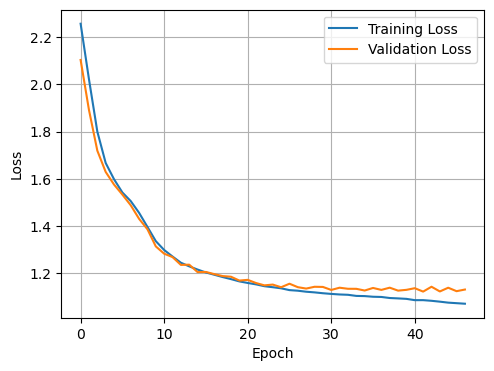

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.savefig('CNN2D2.png')  # Save the figure to a file
plt.grid(True)



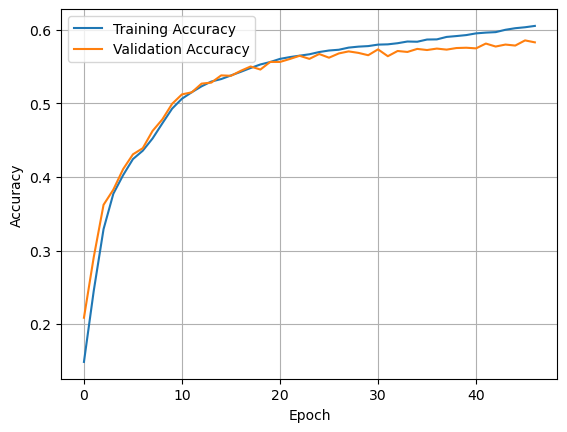

In [30]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.savefig('CNN2D3.png')  # Save the figure to a file
plt.show()

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
import csv

def plot_confusion_matrix(cm, title='Confusion matrix', cmap=plt.get_cmap("PuRd"), labels=[], save_filename=None):
    plt.figure(figsize=(6, 6))
    plt.imshow(cm * 100, interpolation='nearest', cmap=cmap)
    plt.colorbar()
    tick_marks = np.arange(len(labels))
    plt.xticks(tick_marks, labels, rotation=90, size=12)
    plt.yticks(tick_marks, labels, size=12)

    for i in range(len(tick_marks)):
        for j in range(len(tick_marks)):
            value = int(np.around(cm[i, j] * 100))
            if i != j:
                text = plt.text(j, i, f"{value}%", ha="center", va="center", fontsize=10)
            elif i == j:
                if value == 100:
                    text = plt.text(j, i, f"{value}%", ha="center", va="center", fontsize=7, color="white")
                else:
                    text = plt.text(j, i, f"{value}%", ha="center", va="center", fontsize=10, color="white")

    plt.tight_layout()
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    


In [13]:
def calculate_confusion_matrix(Y,Y_hat,classes):
    n_classes = len(classes)
    conf = np.zeros([n_classes,n_classes])
    confnorm = np.zeros([n_classes,n_classes])

    for k in range(0,Y.shape[0]):
        i = list(Y[k,:]).index(1)
        j = int(np.argmax(Y_hat[k,:]))
        conf[i,j] = conf[i,j] + 1

    for i in range(0,n_classes):
        confnorm[i,:] = conf[i,:] / np.sum(conf[i,:])

    right = np.sum(np.diag(conf))
    wrong = np.sum(conf) - right
    return confnorm,right,wrong

In [17]:
from tensorflow.keras.layers import Input,Activation, Conv1D,concatenate, MaxPooling1D, Dropout, GRU, Flatten, Dense, Concatenate, Lambda,Multiply, Add, Subtract, Reshape
from tensorflow.keras.models import Model
import tensorflow as tf

def cal1(x_degrees):
    x_tensor = tf.convert_to_tensor(x_degrees, dtype=tf.float32)
    w = tf.concat([x_tensor * (i + 1) for i in range(128)], axis=-1)
    y = tf.cos(w)
    return tf.expand_dims(y, axis=-1)

def cal2(x_degrees):
    x_tensor = tf.convert_to_tensor(x_degrees, dtype=tf.float32)
    w = tf.concat([x_tensor * (i + 1) for i in range(128)], axis=-1)
    y = tf.sin(w)
    return tf.expand_dims(y, axis=-1)

from tensorflow.keras.layers import Input, Conv2D, Dense, Flatten, Reshape, Concatenate
from tensorflow.keras.models import Model

def CNN(input_shape=(128, 2), input_shape2=(128, 1), classes=11):

    # Define input layers
    dr = 0.5 # dropout rate (%)
    input = Input(shape=input_shape + (1,), name='input1')  # Shape will be (None, 2, 128, 1)
    input1 = Input(input_shape2, name='input2')
    input2 = Input(input_shape2, name='input3')

    x1 = Flatten()(input)
    x1= Dense(80, name='fc1')(x1)
    x1 = Activation('relu')(x1)

    x1= Dense(1, name='fc4')(x1)
    x1 = Activation('linear')(x1)


    cos1= Lambda(cal1)(x1)
    sin1 = Lambda(cal2)(x1)
    x11 = Multiply()([input1, cos1])
    x12 = Multiply()([input2, sin1])
    x21 = Multiply()([input2, cos1])
    x22 = Multiply()([input1, sin1])
    y1 = Add()([x11,x12])
    y2 = Subtract()([x21,x22])
    y1 = Reshape(target_shape=(128, 1), name='reshape1')(y1)
    y2 = Reshape(target_shape=(128, 1), name='reshape2')(y2)
    x11 = concatenate([y1, y2])
    x3 = Reshape(target_shape=((128, 2, 1)), name='reshape3')(x11)

    # spatial feature
    x3 = Conv2D(75, (8,2), padding='valid', activation="relu", name="conv1_1", kernel_initializer='glorot_uniform')(
        x3)
    x3 = Conv2D(25, (5,1), padding='valid', activation="relu", name="conv1_2", kernel_initializer='glorot_uniform')(
        x3)
    # temporal feature
    x4 = Reshape(target_shape=((117,25)), name='reshape4')(x3)
    x4= GRU(units=128)(x4)

    x = Dense(classes, activation='softmax', name='softmax')(x4)
                                                             

    model = Model(inputs = [input,input1,input2], outputs=x)



    return model




In [18]:
from keras.optimizers import Adam
model=CNN()
from keras.optimizers import AdamW
from keras.optimizers.schedules import ExponentialDecay



model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input1 (InputLayer) │ (None, 128, 2, 1) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 256)       │          0 │ input1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fc1 (Dense)         │ (None, 80)        │     20,560 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 80)        │          0 │ fc1[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fc4 (Dense)         │ (None, 1)         │         81 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 1)         │          0 │ fc4[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input2 (InputLayer) │ (None, 128, 1)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_2 (Lambda)   │ (None, 128, 1)    │          0 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input3 (InputLayer) │ (None, 128, 1)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_3 (Lambda)   │ (None, 128, 1)    │          0 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_4          │ (None, 128, 1)    │          0 │ input2[0][0],     │
│ (Multiply)          │                   │            │ lambda_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_5          │ (None, 128, 1)    │          0 │ input3[0][0],     │
│ (Multiply)          │                   │            │ lambda_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_6          │ (None, 128, 1)    │          0 │ input3[0][0],     │
│ (Multiply)          │                   │            │ lambda_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_7          │ (None, 128, 1)    │          0 │ input2[0][0],     │
│ (Multiply)          │                   │            │ lambda_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 128, 1)    │          0 │ multiply_4[0][0], │
│                     │                   │            │ multiply_5[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subtract_1          │ (None, 128, 1)    │          0 │ multiply_6[0][0], │
│ (Subtract)          │                   │            │ multiply_7[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape1 (Reshape)  │ (None, 128, 1)    │          0 │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape2 (Reshape)  │ (None, 128, 1)    │          0 │ subtract_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 128, 2)    │          0 │ reshape1[0][0],   │
│ (Concatenate)       │                   │            │ reshape2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape3 (Reshape)  │ (None, 128, 2, 1) │          0 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 92,255 (360.37 KB)

 Trainable params: 92,255 (360.37 KB)

 Non-trainable params: 0 (0.00 B)

In [59]:
from keras import callbacks
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, Reshape,GRU
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import callbacks
from tensorflow.keras.callbacks import ModelCheckpoint,ReduceLROnPlateau,EarlyStopping

modtype=['8PSK','AM-DSB','AM-SSB','BPSK','CPFSK','GFSK','4-PAM','16-QAM','64-QAM','QPSK','WBFM']
filepath =('/content/drive/MyDrive/Colab Notebooks/frequency_weights80.h5')
history=model.fit([X_train, X1_train, X2_train], Y_train, epochs=100, batch_size=64,
         validation_data=([X_val, X1_val, X2_val], Y_val),callbacks = [
                ModelCheckpoint('marah_GRU_CNN2.h', monitor='val_loss', verbose=1, save_best_only=True, mode='auto'),
                ReduceLROnPlateau(monitor='val_loss',factor=0.5,verbose=1,patince=5,min_lr=0.0000001),
                EarlyStopping(monitor='val_loss', patience=5, verbose=1, mode='auto'),
                ])


Epoch 1/100
1960/1960 [==============================] - ETA: 0s - loss: 1.8858 - accuracy: 0.2849
Epoch 1: val_loss improved from inf to 1.52853, saving model to marah_GRU_CNN2.h
INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


1960/1960 [==============================] - 39s 19ms/step - loss: 1.8858 - accuracy: 0.2849 - val_loss: 1.5285 - val_accuracy: 0.4231 - lr: 0.0010
Epoch 2/100
1960/1960 [==============================] - ETA: 0s - loss: 1.3679 - accuracy: 0.4744
Epoch 2: val_loss improved from 1.52853 to 1.23768, saving model to marah_GRU_CNN2.h
INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


1960/1960 [==============================] - 34s 17ms/step - loss: 1.3679 - accuracy: 0.4744 - val_loss: 1.2377 - val_accuracy: 0.5149 - lr: 0.0010
Epoch 3/100
1957/1960 [============================>.] - ETA: 0s - loss: 1.2062 - accuracy: 0.5331
Epoch 3: val_loss improved from 1.23768 to 1.16082, saving model to marah_GRU_CNN2.h
INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


... (21 outputs left out)

INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


1960/1960 [==============================] - 34s 17ms/step - loss: 0.9715 - accuracy: 0.6462 - val_loss: 1.0023 - val_accuracy: 0.6356 - lr: 0.0010
Epoch 23/100
1955/1960 [============================>.] - ETA: 0s - loss: 0.9676 - accuracy: 0.6488
Epoch 23: val_loss did not improve from 1.00230
1960/1960 [==============================] - 31s 16ms/step - loss: 0.9676 - accuracy: 0.6488 - val_loss: 1.0045 - val_accuracy: 0.6363 - lr: 0.0010
Epoch 24/100
1956/1960 [============================>.] - ETA: 0s - loss: 0.9615 - accuracy: 0.6512
Epoch 24: val_loss did not improve from 1.00230
1960/1960 [==============================] - 32s 16ms/step - loss: 0.9616 - accuracy: 0.6512 - val_loss: 1.0112 - val_accuracy: 0.6312 - lr: 0.0010
Epoch 25/100
1960/1960 [==============================] - ETA: 0s - loss: 0.9589 - accuracy: 0.6520
Epoch 25: val_loss improved from 1.00230 to 1.00142, saving model to marah_GRU_CNN2.h
INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


INFO:tensorflow:Assets written to: marah_GRU_CNN2.h/assets


1960/1960 [==============================] - 36s 19ms/step - loss: 0.9589 - accuracy: 0.6520 - val_loss: 1.0014 - val_accuracy: 0.6353 - lr: 0.0010
Epoch 26/100
1959/1960 [============================>.] - ETA: 0s - loss: 0.9560 - accuracy: 0.6529
Epoch 26: val_loss did not improve from 1.00142
1960/1960 [==============================] - 29s 15ms/step - loss: 0.9559 - accuracy: 0.6529 - val_loss: 1.0135 - val_accuracy: 0.6355 - lr: 0.0010
Epoch 27/100
1957/1960 [============================>.] - ETA: 0s - loss: 0.9558 - accuracy: 0.6523
Epoch 27: val_loss did not improve from 1.00142
1960/1960 [==============================] - 31s 16ms/step - loss: 0.9559 - accuracy: 0.6522 - val_loss: 1.0045 - val_accuracy: 0.6390 - lr: 0.0010
Epoch 28/100
1956/1960 [============================>.] - ETA: 0s - loss: 0.9508 - accuracy: 0.6557
Epoch 28: val_loss did not improve from 1.00142
1960/1960 [==============================] - 30s 16ms/step - loss: 0.9508 - accuracy: 0.6557 - val_loss: 1.0266 

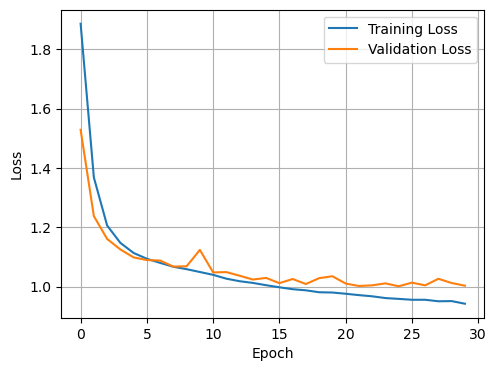

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.savefig('CNN2D2_801.png')  # Save the figure to a file
plt.grid(True)



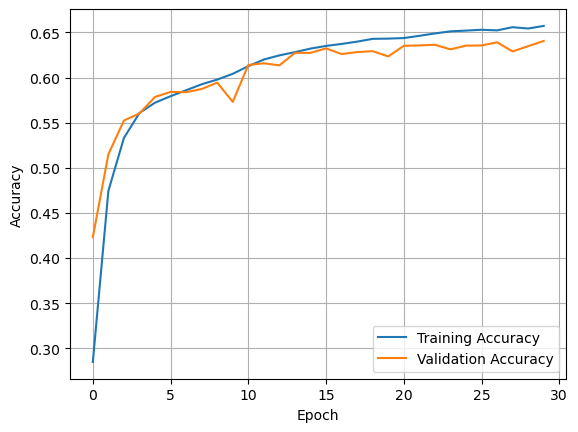

In [61]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.savefig('CNN2D3801.png')  # Save the figure to a file
plt.show()

In [19]:
model.load_weights('CNN_80ff.h5')


1375/1375 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step


<Figure size 1200x1000 with 0 Axes>

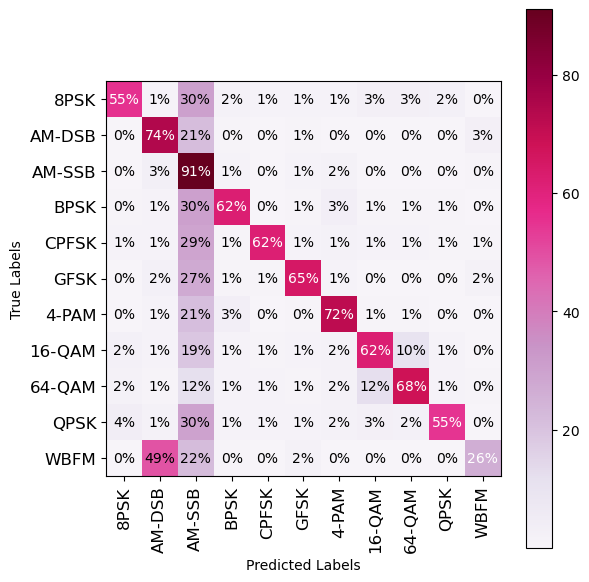

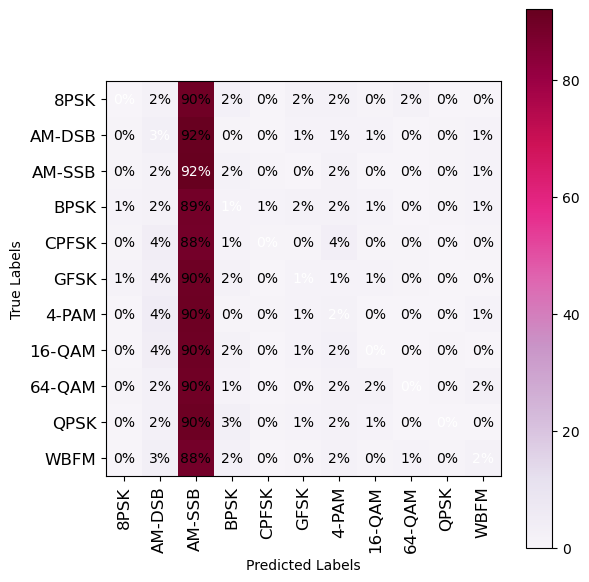

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

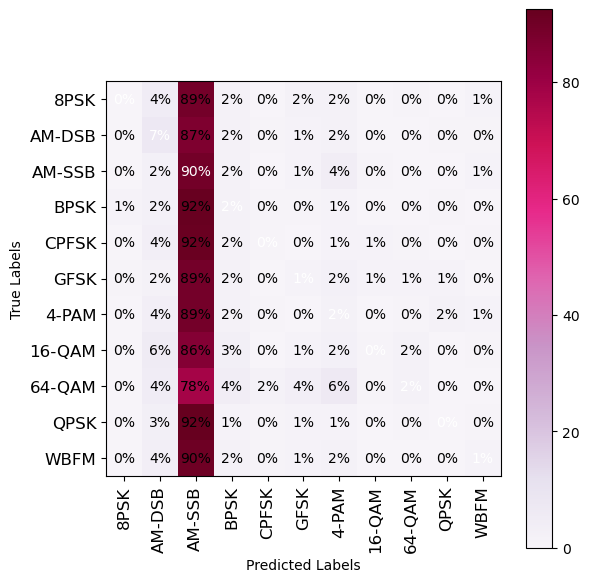

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

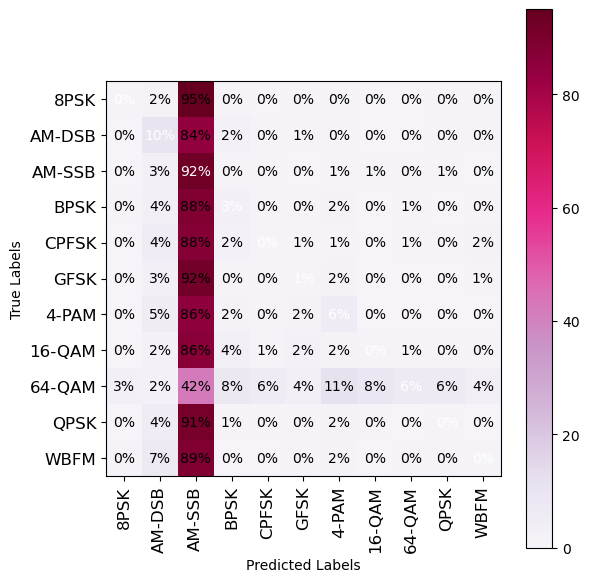

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

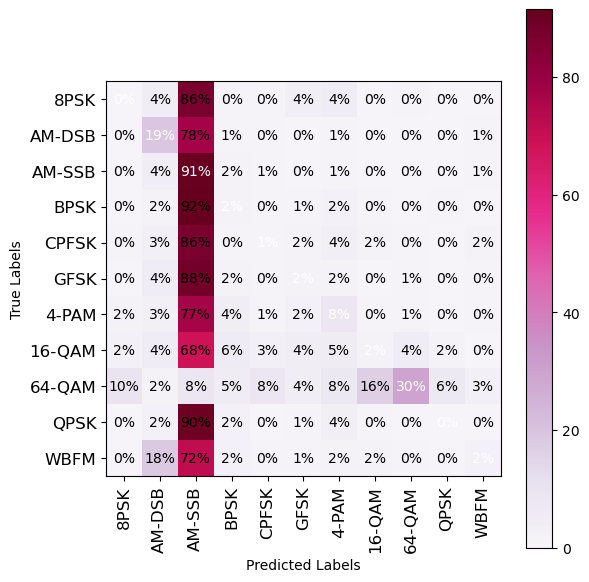

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

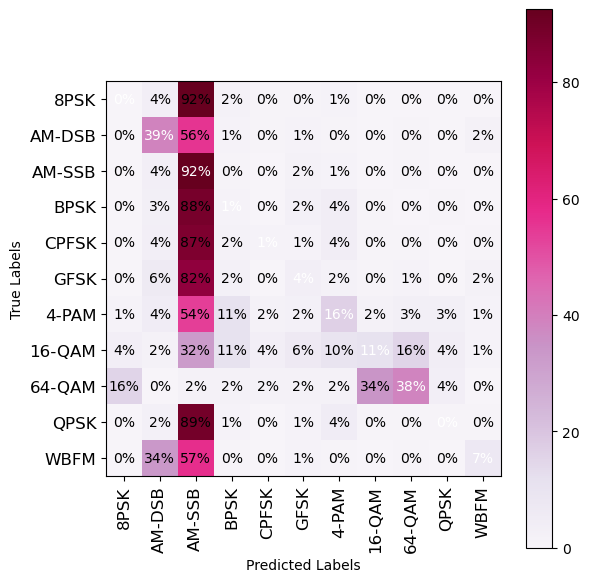

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

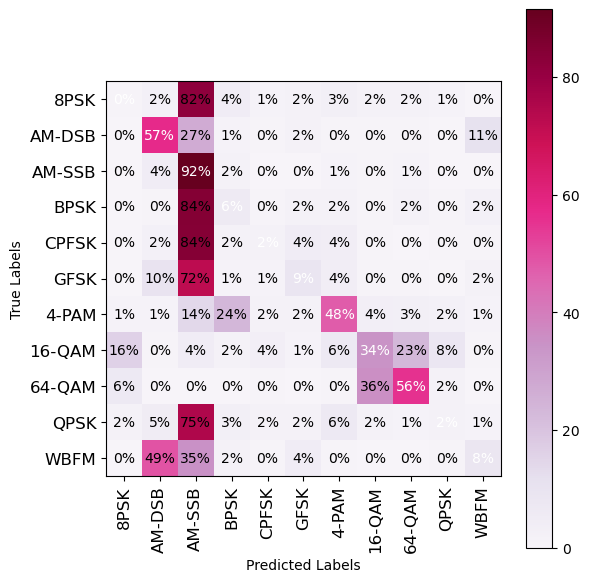

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

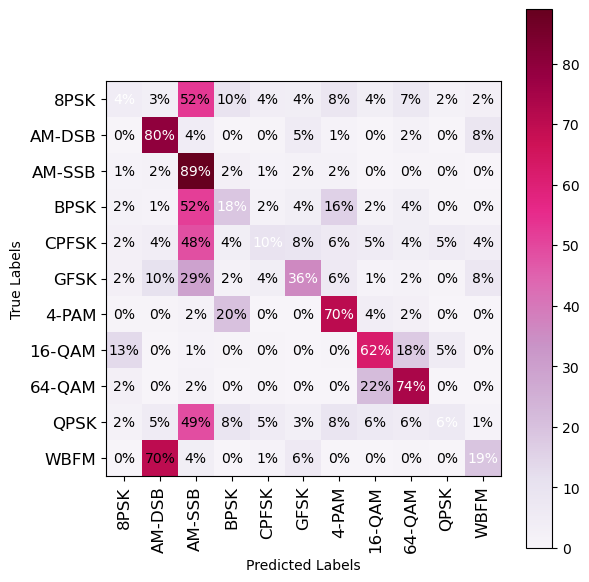

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

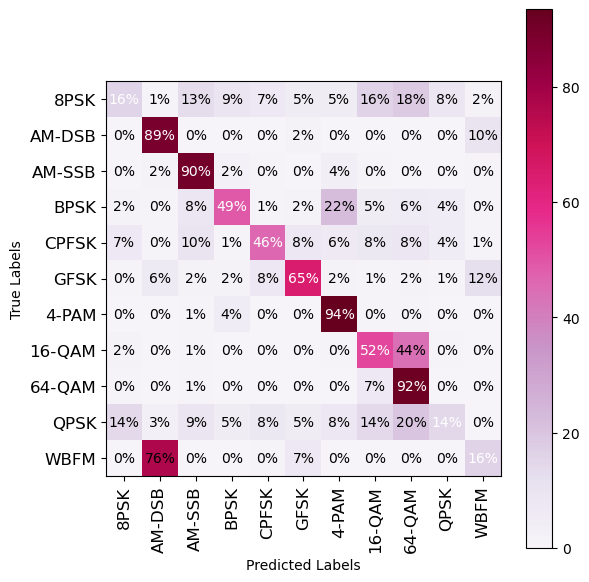

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

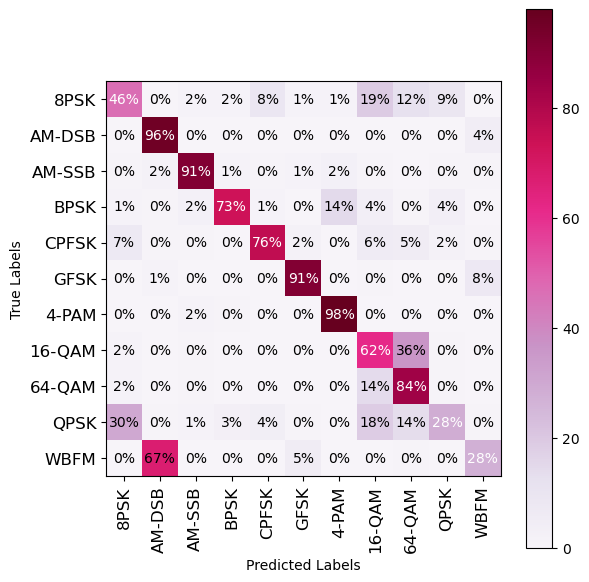

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

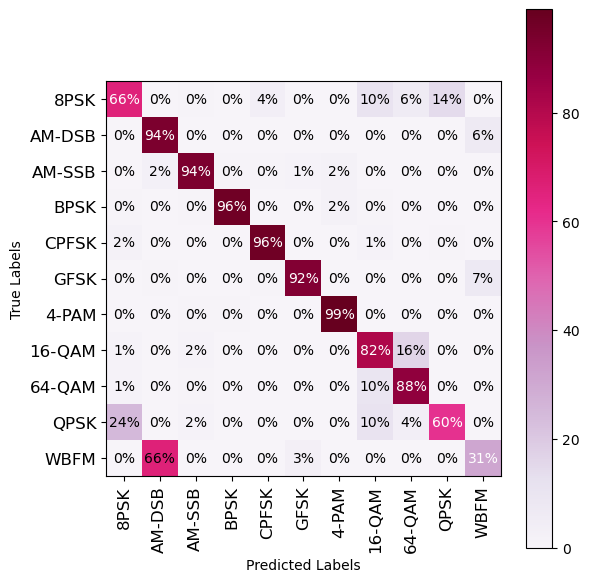

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

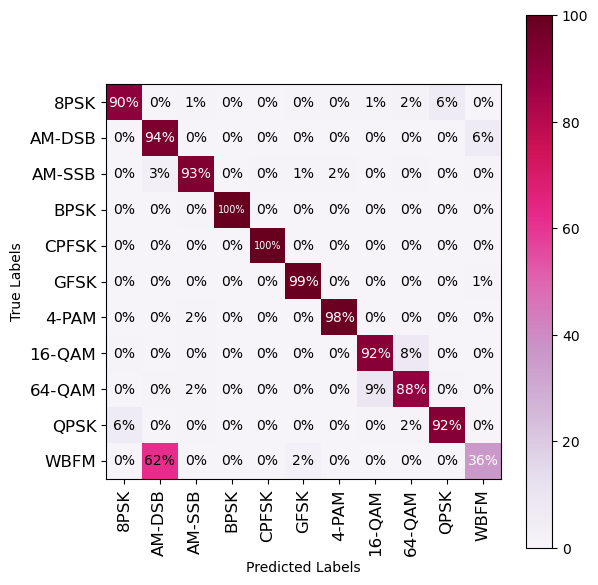

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

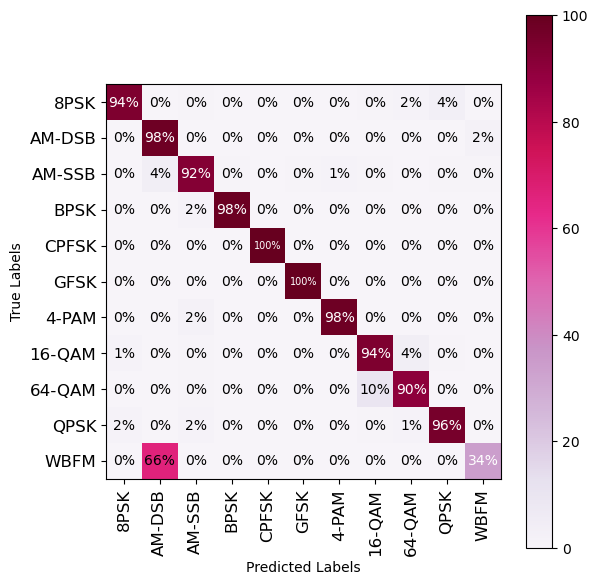

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

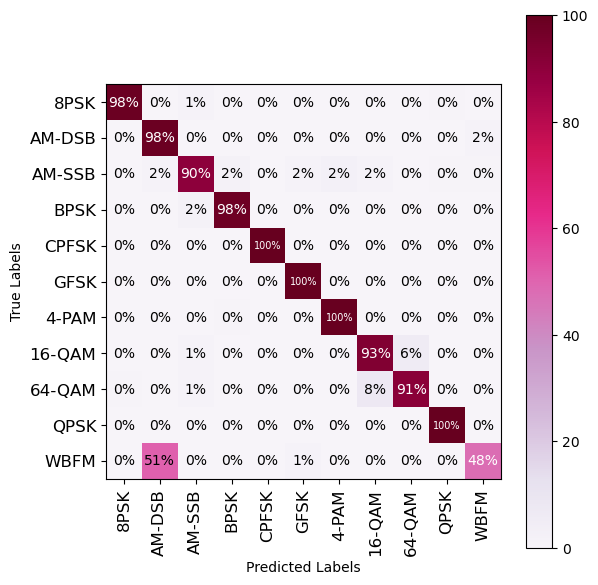

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

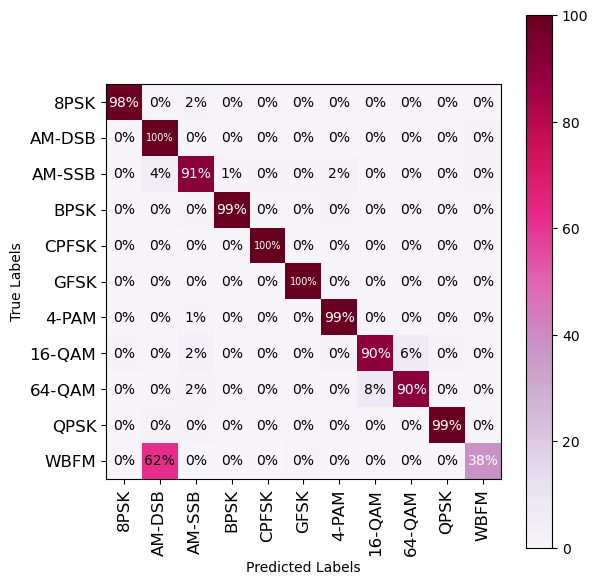

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

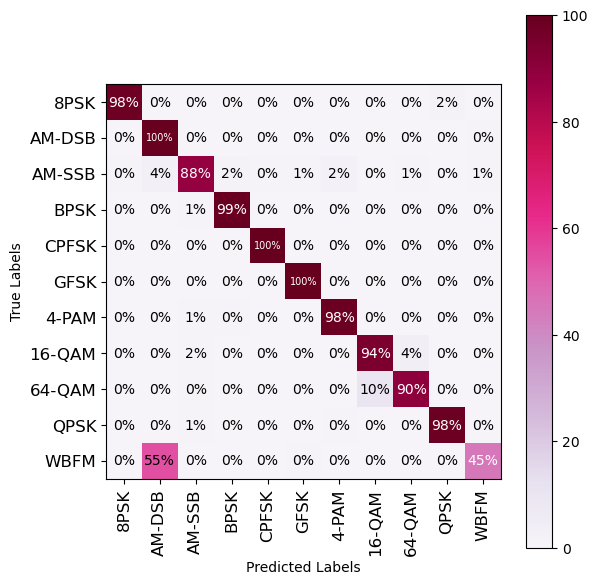

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

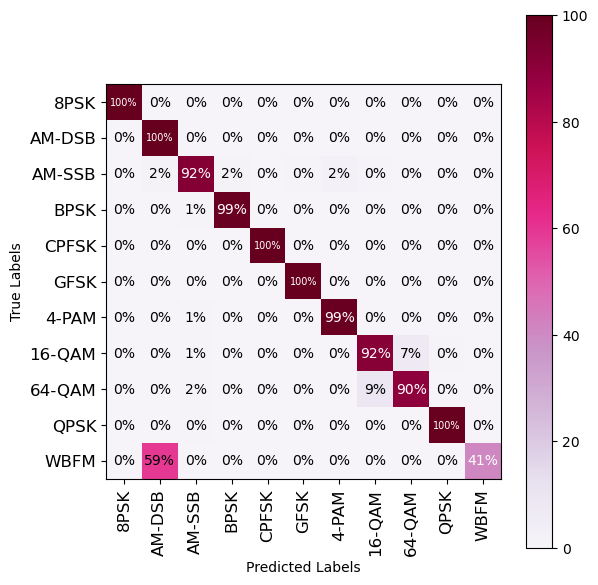

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

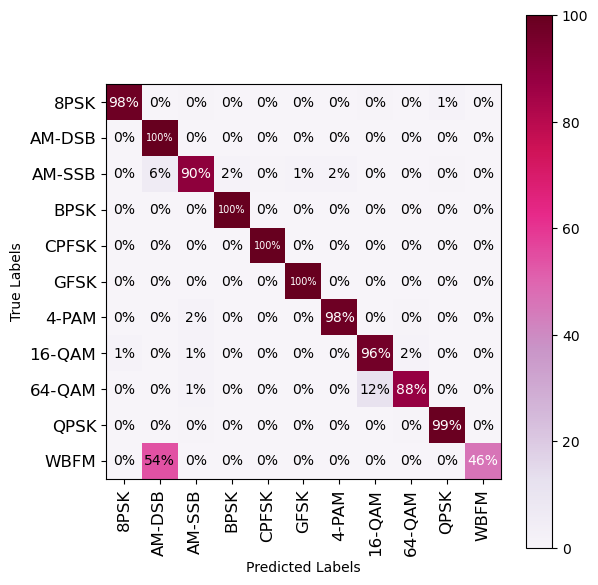

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

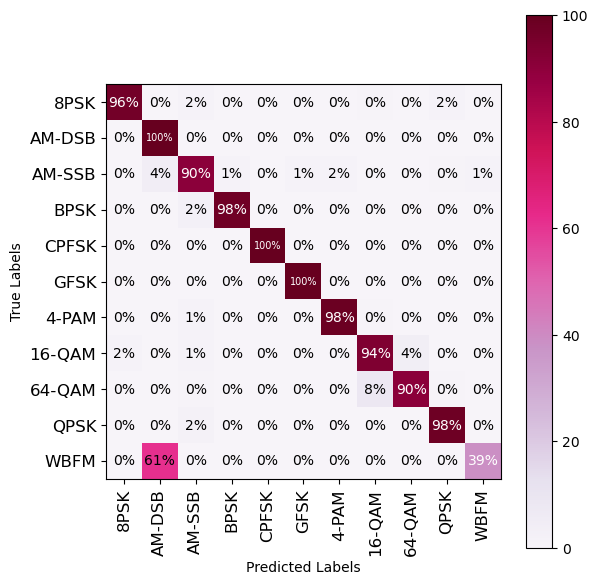

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

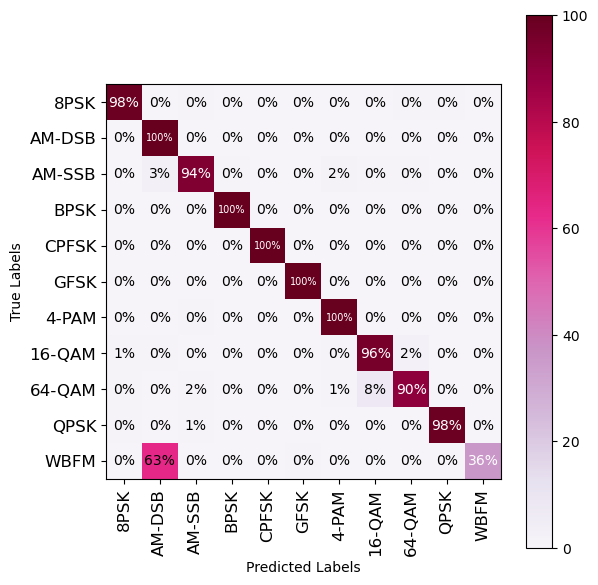

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

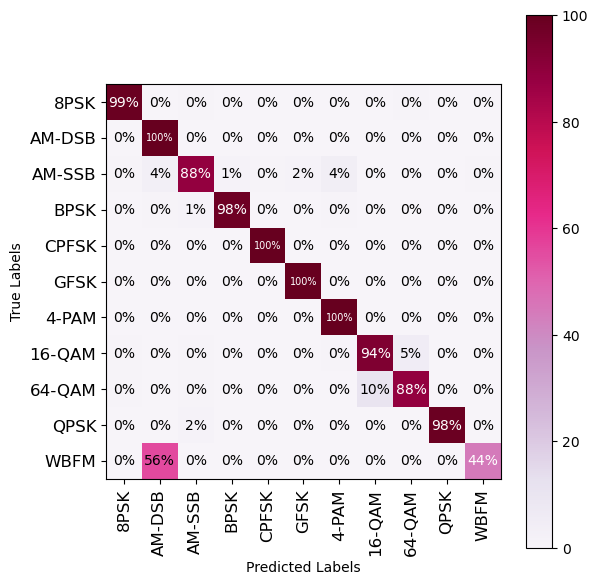

<Figure size 640x480 with 0 Axes>

In [20]:
model.load_weights('CNN_80ff.h5')

plt.figure(figsize=(12, 10))  # Example size, adjust as needed
test_Y_hat = model.predict([X_test, X1_test, X2_test], batch_size=32)
confnorm, _, _ = calculate_confusion_matrix(Y_test, test_Y_hat, classes)
snrs1=snrs
plot_confusion_matrix(confnorm, labels=modtype)
acc1 = {}
acc_mod_snr = np.zeros( (len(classes),len(snrs)) )
i = 0
for snr in snrs1:
        test_SNRs = [lbl[x][1] for x in test_idx]
        test_X_i=X_test[np.where(np.array(test_SNRs) == snr)]
        test_X1_i = X1_test[np.where(np.array(test_SNRs) == snr)]
        test_X2_i = X2_test[np.where(np.array(test_SNRs) == snr)]
        test_Y_i = Y_test[np.where(np.array(test_SNRs) == snr)]

      
        test_Y_i_hat = model.predict([test_X_i,test_X1_i,test_X2_i])
        
        confnorm_i,cor,ncor = calculate_confusion_matrix(test_Y_i,test_Y_i_hat,classes)
        acc1[snr] = 1.0 * cor / (cor + ncor)
        plot_confusion_matrix(confnorm_i, labels=['8PSK','AM-DSB','AM-SSB','BPSK','CPFSK','GFSK','4-PAM','16-QAM','64-QAM','QPSK','WBFM'])
        plt.show()  # Display the plot
        plt.savefig('figure3.png')  # Save the figure to a file

        acc_mod_snr[:,i] = np.round(np.diag(confnorm_i)/np.sum(confnorm_i,axis=1),3)
        i = i +1


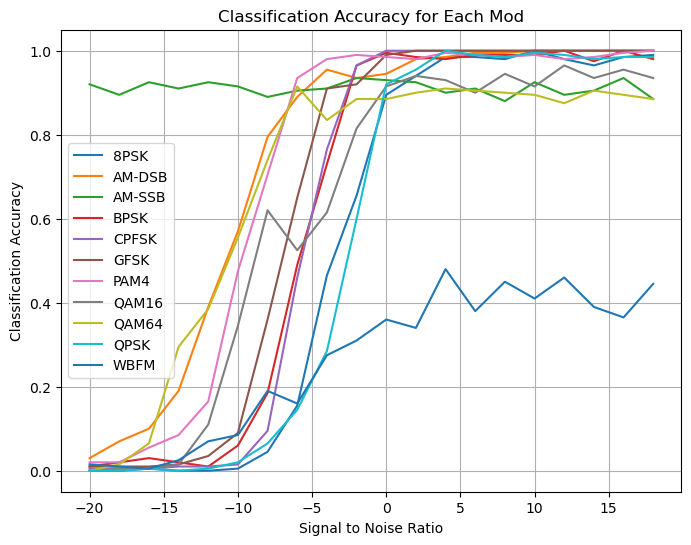

In [21]:
import numpy as np
import matplotlib.pyplot as plt

num_mod = 11

plt.figure(figsize=(8, 6))
plt.xlabel("Signal to Noise Ratio")
plt.ylabel("Classification Accuracy")
plt.title("Classification Accuracy for Each Mod")

for i in range(0, num_mod):
    plt.plot(snrs1, acc_mod_snr[i], label=classes[i])

# Add legend, grid, save, and show plot
plt.legend()
plt.grid()
plt.savefig('marah.png')  
plt.show() 
plt.close()


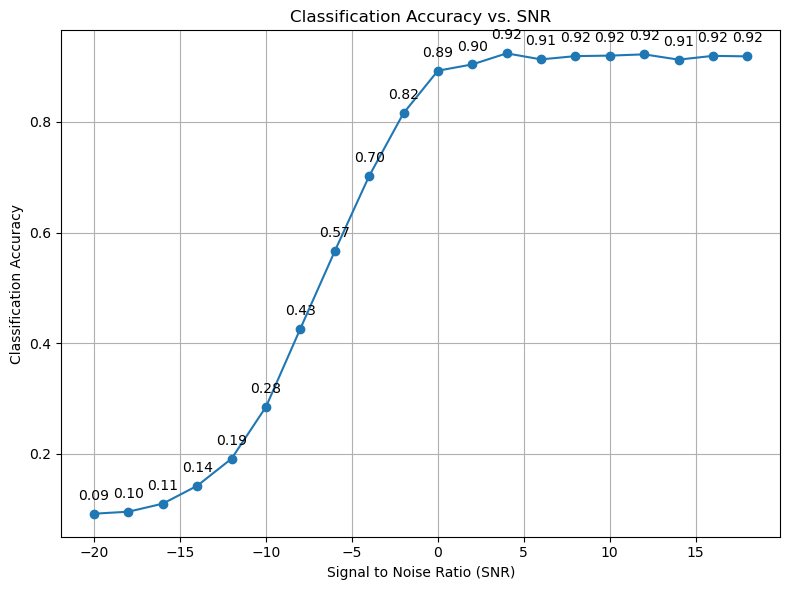

In [22]:
# Plot Accuracy vs. SNR
plt.figure(figsize=(8, 6))

plt.plot(snrs, list(map(lambda x: acc1[x], snrs1)), marker='o', label='freq')

# Annotate each point with its value
for snr, accuracy in zip(snrs, list(map(lambda x: acc1[x], snrs1))):
    plt.annotate(f'{accuracy:.2f}',
                 (snr, accuracy),
                 textcoords="offset points",
                 xytext=(0,10),
                 ha='center')
# Adding labels and title
plt.xlabel("Signal to Noise Ratio (SNR)")
plt.ylabel("Classification Accuracy")
plt.title("Classification Accuracy vs. SNR")
plt.grid(True)
plt.tight_layout()

# Save the figure to a file and show it
plt.savefig('figure1.png')  # Save the figure to a file
plt.show()

In [23]:
from tensorflow.keras.layers import Input,Activation, Conv1D,concatenate, MaxPooling1D, Dropout, GRU, Flatten, Dense, Concatenate, Lambda,Multiply, Add, Subtract, Reshape
from tensorflow.keras.models import Model
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, Dense, Flatten, Reshape, Concatenate

def CNN(input_shape=(128, 2), input_shape2=(128, 1), classes=11):

    # Define input layers
    dr = 0.5 # dropout rate (%)
    input = Input(shape=input_shape + (1,), name='input1')  # Shape will be (None, 2, 128, 1)
    input1 = Input(input_shape2, name='input2')
    input2 = Input(input_shape2, name='input3')



    # spatial feature
    x3 = Conv2D(75, (8,2), padding='valid', activation="relu", name="conv1_1", kernel_initializer='glorot_uniform')(
        input)
    x3 = Conv2D(25, (5,1), padding='valid', activation="relu", name="conv1_2", kernel_initializer='glorot_uniform')(
        x3)
    # temporal feature
    x4 = Reshape(target_shape=((117,25)), name='reshape4')(x3)
    x4= GRU(units=128)(x4)

    x = Dense(classes, activation='softmax', name='softmax')(x4)
                                                             

    model = Model(inputs = [input,input1,input2], outputs=x)



    return model




In [24]:
from keras.optimizers import Adam
model=CNN()
from keras.optimizers import AdamW
from keras.optimizers.schedules import ExponentialDecay



model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input1 (InputLayer) │ (None, 128, 2, 1) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_1 (Conv2D)    │ (None, 121, 1,    │      1,275 │ input1[0][0]      │
│                     │ 75)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_2 (Conv2D)    │ (None, 117, 1,    │      9,400 │ conv1_1[0][0]     │
│                     │ 25)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape4 (Reshape)  │ (None, 117, 25)   │          0 │ conv1_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_3 (GRU)         │ (None, 128)       │     59,520 │ reshape4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input2 (InputLayer) │ (None, 128, 1)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input3 (InputLayer) │ (None, 128, 1)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ softmax (Dense)     │ (None, 11)        │      1,419 │ gru_3[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 71,614 (279.74 KB)

 Trainable params: 71,614 (279.74 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from keras import callbacks
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, Reshape,GRU
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import callbacks
from tensorflow.keras.callbacks import ModelCheckpoint,ReduceLROnPlateau,EarlyStopping

modtype=['8PSK','AM-DSB','AM-SSB','BPSK','CPFSK','GFSK','4-PAM','16-QAM','64-QAM','QPSK','WBFM']
filepath =('/content/drive/MyDrive/Colab Notebooks/frequency_weights80.h5')
history=model.fit([X_train, X1_train, X2_train], Y_train, epochs=100, batch_size=64,
         validation_data=([X_val, X1_val, X2_val], Y_val),callbacks = [
                ModelCheckpoint('marah_GRU_CNN2.keras', monitor='val_loss', verbose=1, save_best_only=True, mode='auto'),
                ReduceLROnPlateau(monitor='val_loss',factor=0.5,verbose=1,patince=5,min_lr=0.0000001),
                EarlyStopping(monitor='val_loss', patience=5, verbose=1, mode='auto'),
                ])


1375/1375 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step


<Figure size 1200x1000 with 0 Axes>

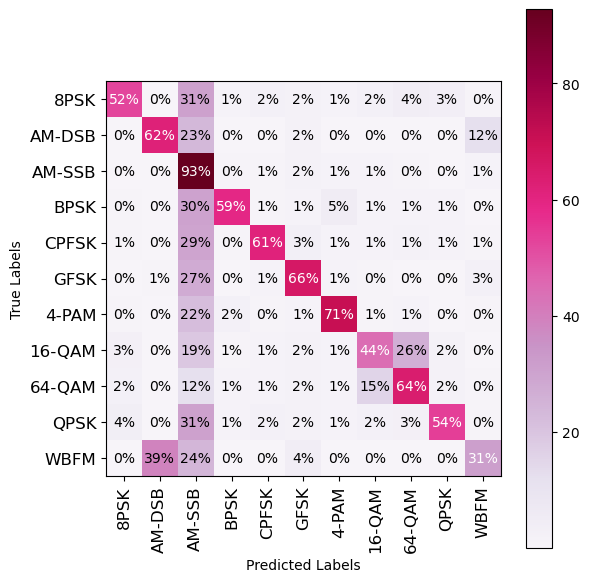

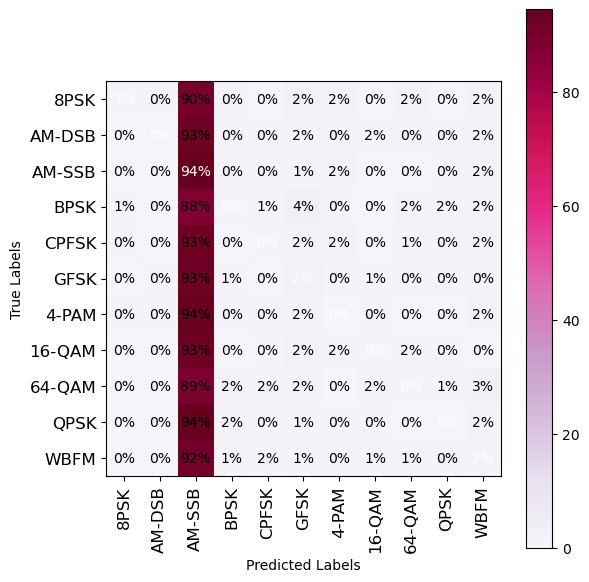

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

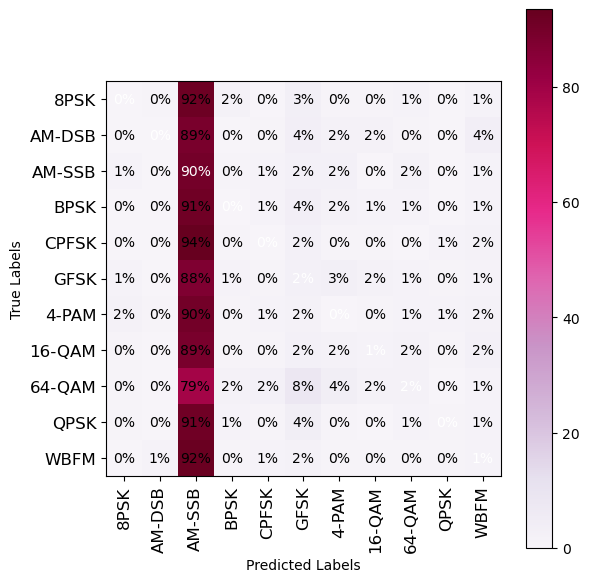

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

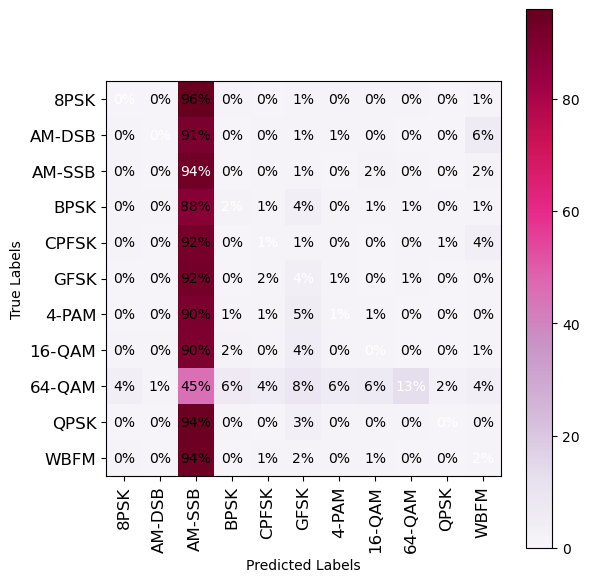

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

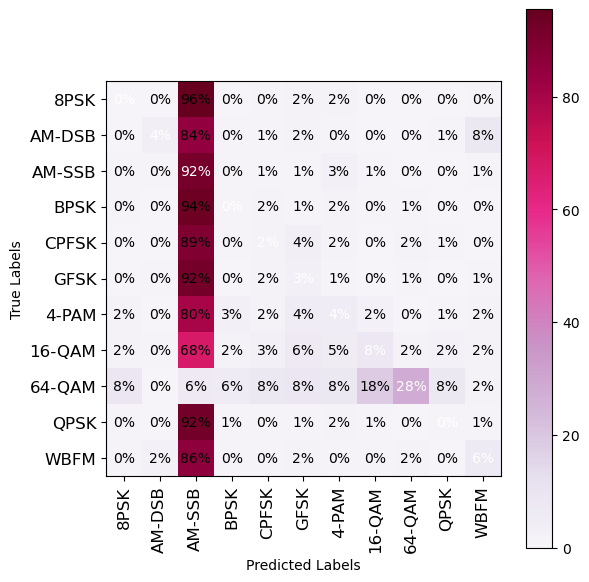

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

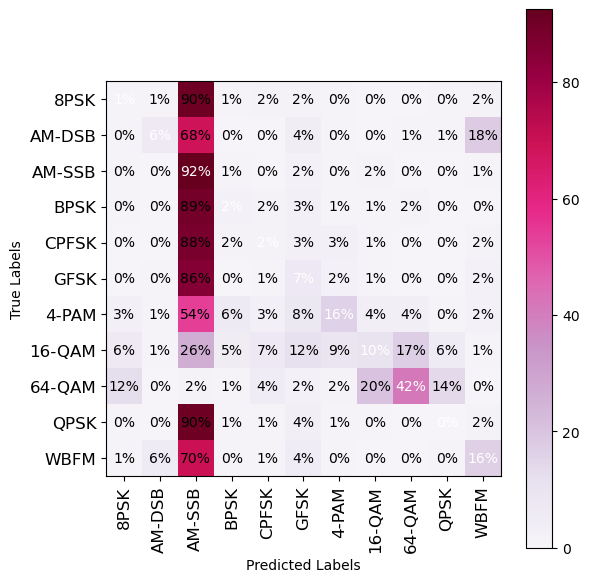

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

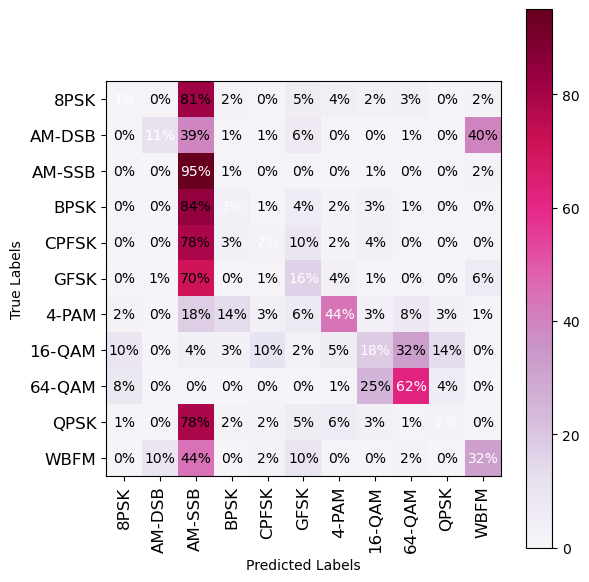

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

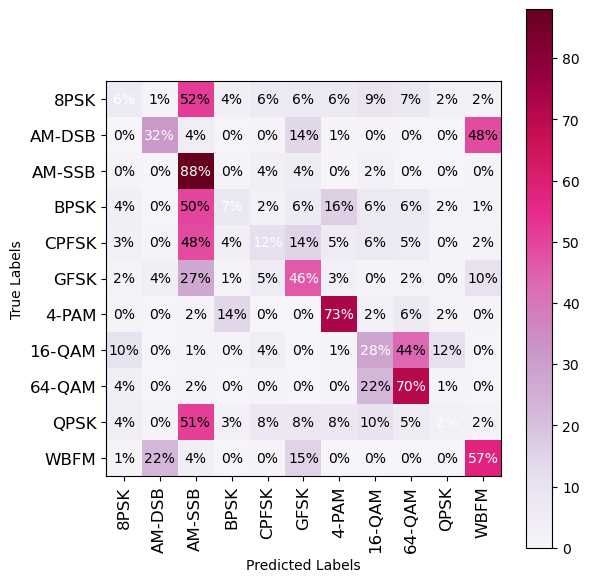

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

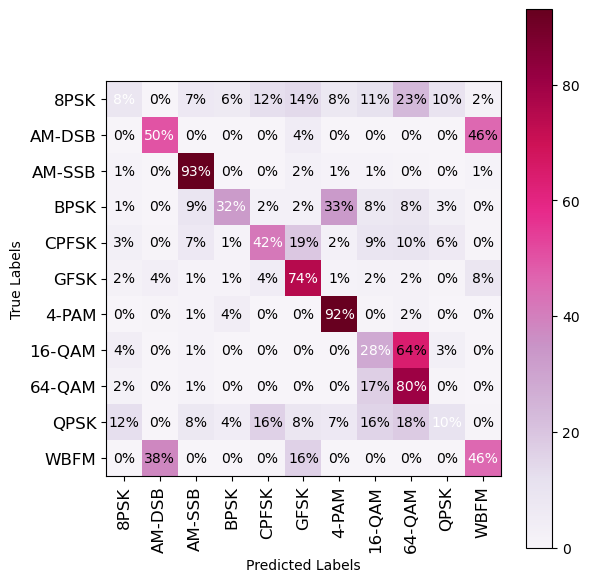

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

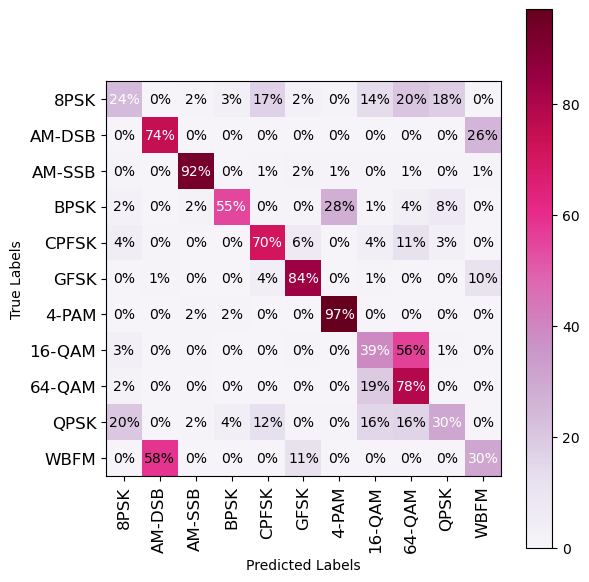

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

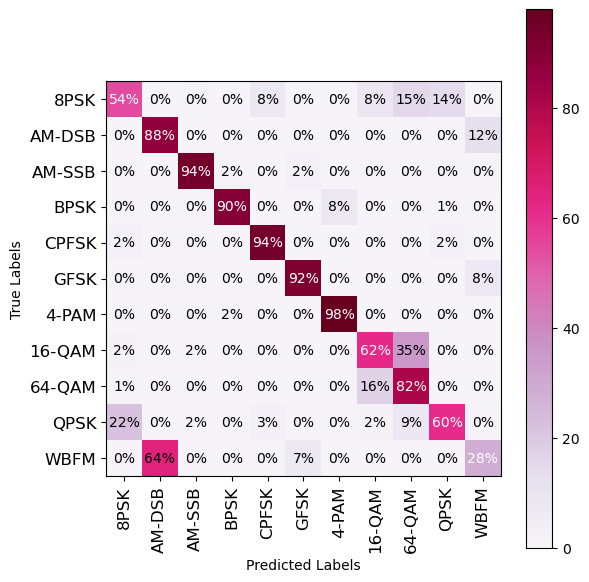

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

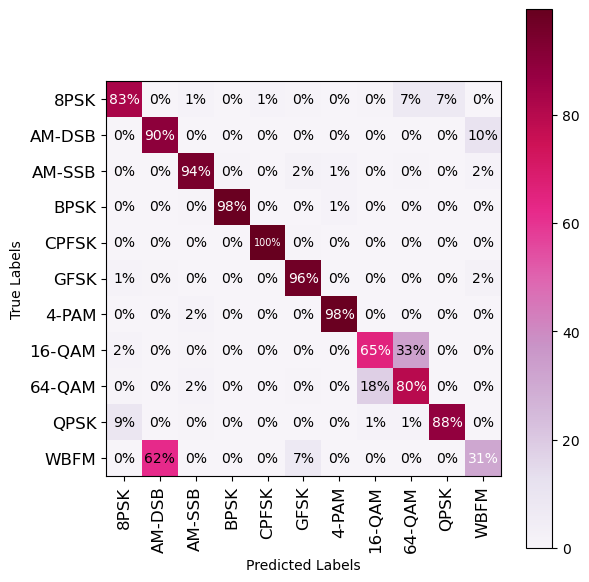

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

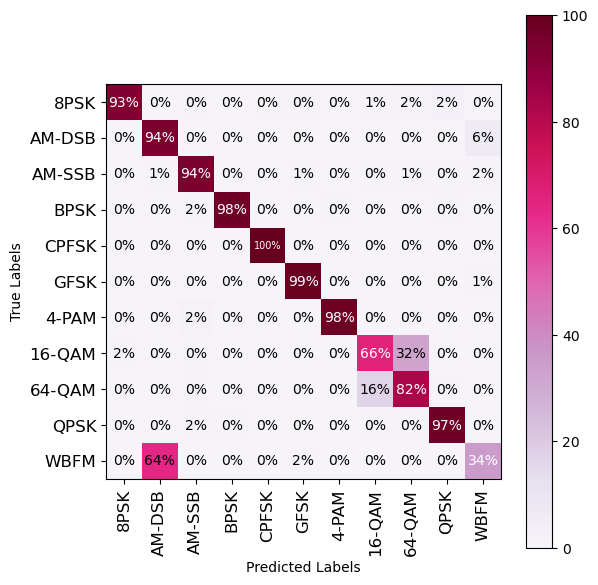

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

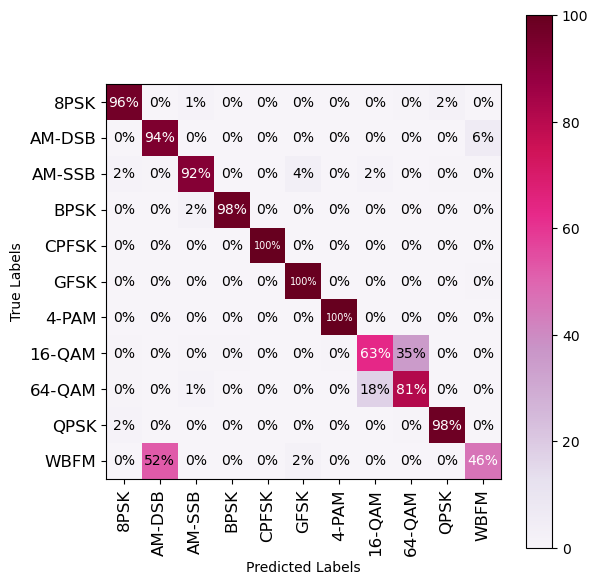

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

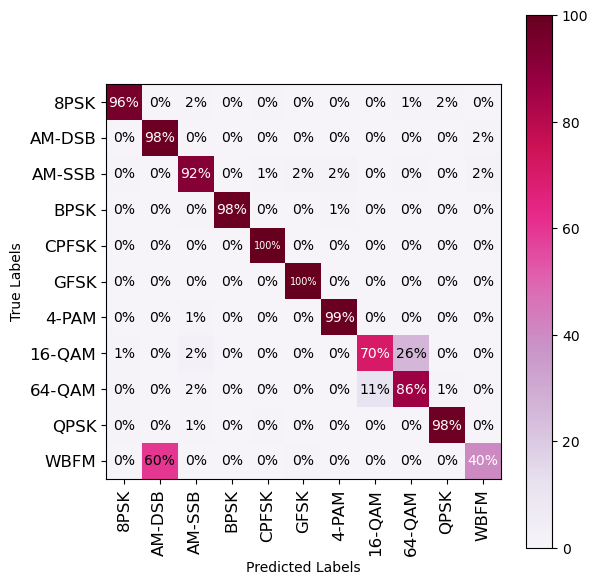

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

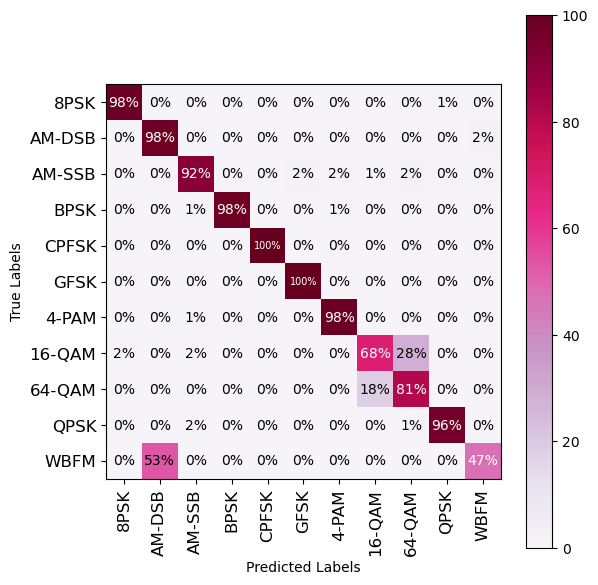

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


<Figure size 640x480 with 0 Axes>

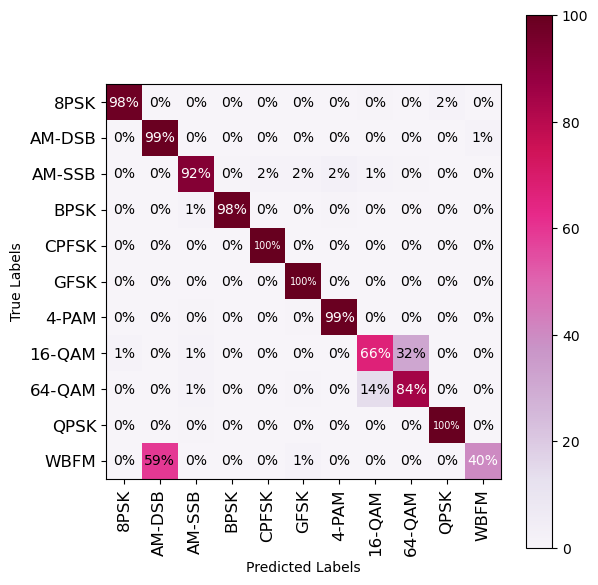

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

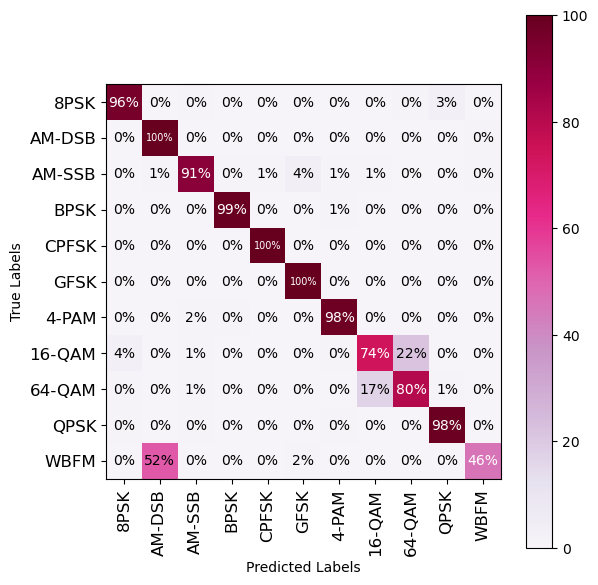

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

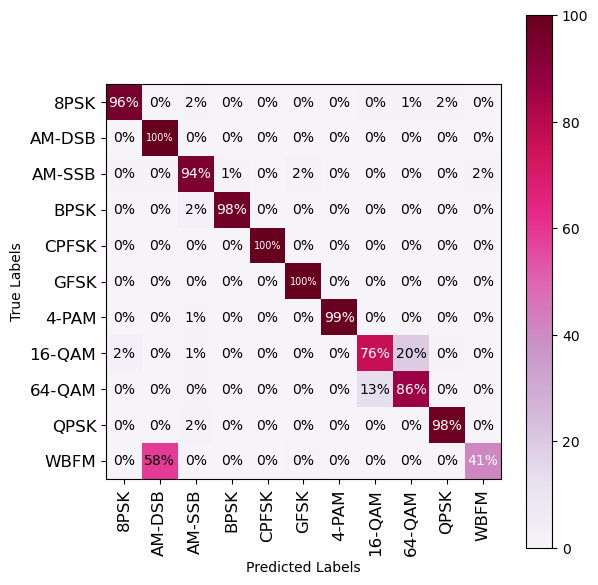

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

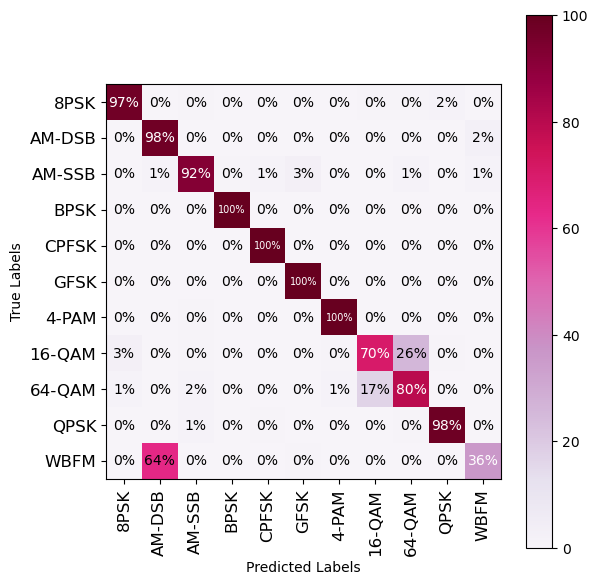

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Figure size 640x480 with 0 Axes>

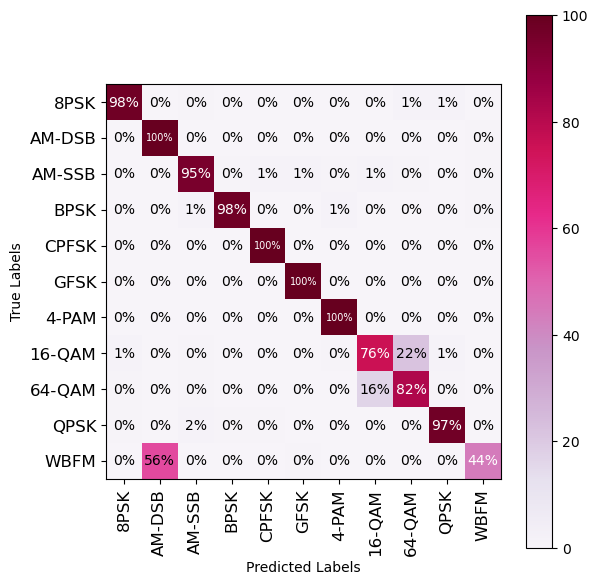

<Figure size 640x480 with 0 Axes>

In [28]:
model.load_weights('CNN_2D_weights.h5')
plt.figure(figsize=(12, 10))  
test_Y_hat = model.predict([X_test, X1_test, X2_test], batch_size=32)
confnorm, _, _ = calculate_confusion_matrix(Y_test, test_Y_hat, classes)
snrs1=snrs
plot_confusion_matrix(confnorm, labels=modtype)
acc2= {}
acc_mod_snr = np.zeros( (len(classes),len(snrs)) )
i = 0
for snr in snrs1:
        test_SNRs = [lbl[x][1] for x in test_idx]
        test_X_i=X_test[np.where(np.array(test_SNRs) == snr)]
        test_X1_i = X1_test[np.where(np.array(test_SNRs) == snr)]
        test_X2_i = X2_test[np.where(np.array(test_SNRs) == snr)]
        test_Y_i = Y_test[np.where(np.array(test_SNRs) == snr)]

      
        test_Y_i_hat = model.predict([test_X_i,test_X1_i,test_X2_i])
        
        confnorm_i,cor,ncor = calculate_confusion_matrix(test_Y_i,test_Y_i_hat,classes)
        acc2[snr] = 1.0 * cor / (cor + ncor)

        plot_confusion_matrix(confnorm_i, labels=['8PSK','AM-DSB','AM-SSB','BPSK','CPFSK','GFSK','4-PAM','16-QAM','64-QAM','QPSK','WBFM'])
        plt.show()  # Display the plot
        plt.savefig('figure3.png')  # Save the figure to a file

        acc_mod_snr[:,i] = np.round(np.diag(confnorm_i)/np.sum(confnorm_i,axis=1),3)
        i = i +1



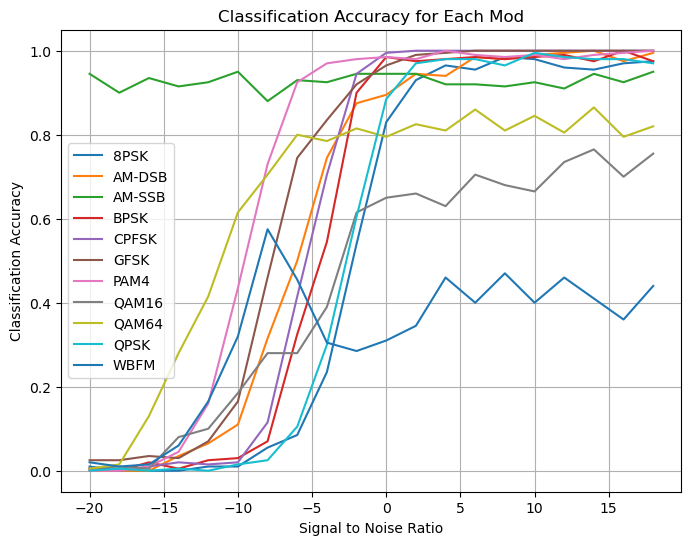

In [29]:
import numpy as np
import matplotlib.pyplot as plt

num_mod = 11

plt.figure(figsize=(8, 6))
plt.xlabel("Signal to Noise Ratio")
plt.ylabel("Classification Accuracy")
plt.title("Classification Accuracy for Each Mod")

for i in range(0, num_mod):
    plt.plot(snrs1, acc_mod_snr[i], label=classes[i])

# Add legend, grid, save, and show plot
plt.legend()
plt.grid()
plt.savefig('marah.png')  
plt.show() 
plt.close()


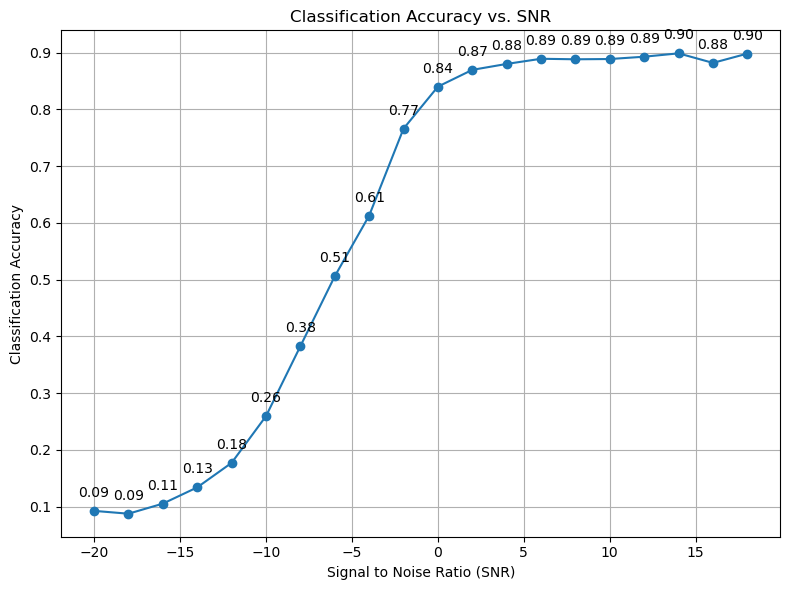

In [31]:
# Plot Accuracy vs. SNR
plt.figure(figsize=(8, 6))

plt.plot(snrs, list(map(lambda x: acc2[x], snrs1)), marker='o', label='freq')

for snr, accuracy in zip(snrs, list(map(lambda x: acc2[x], snrs1))):
    plt.annotate(f'{accuracy:.2f}',
                 (snr, accuracy),
                 textcoords="offset points",
                 xytext=(0,10),
                 ha='center')
plt.xlabel("Signal to Noise Ratio (SNR)")
plt.ylabel("Classification Accuracy")
plt.title("Classification Accuracy vs. SNR")
plt.grid(True)
plt.tight_layout()

plt.savefig('figure1.png')  # Save the figure to a file
plt.show()

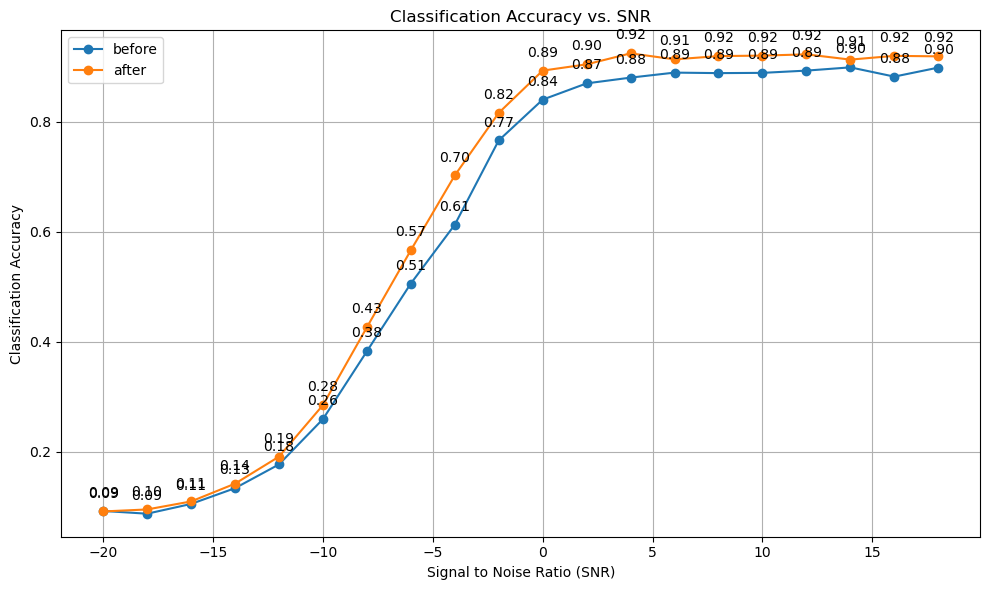

In [33]:
# Plot Accuracy vs. SNR
plt.figure(figsize=(10, 6))
plt.plot(snrs, list(map(lambda x: acc2[x], snrs)), marker='o', label='before')

# Annotate each point with its value
for snr, accuracy in zip(snrs, list(map(lambda x: acc2[x], snrs))):
    plt.annotate(f'{accuracy:.2f}',
                 (snr, accuracy),
                 textcoords="offset points",
                 xytext=(0,10),
                 ha='center')
plt.plot(snrs, list(map(lambda x: acc1[x], snrs)), marker='o', label='after')

# Annotate each point with its value
for snr, accuracy in zip(snrs, list(map(lambda x: acc1[x], snrs))):
    plt.annotate(f'{accuracy:.2f}',
                 (snr, accuracy),
                 textcoords="offset points",
                 xytext=(0,10),
                 ha='center')
    
#plt.plot(snrs, list(map(lambda x: acc1[x], snrs1)), marker='o', label='without')

# Annotate each point with its value


# Adding labels and title
plt.xlabel("Signal to Noise Ratio (SNR)")
plt.ylabel("Classification Accuracy")
plt.title("Classification Accuracy vs. SNR")
plt.grid(True)
plt.legend()
plt.tight_layout()

# Save the figure to a file and show it
plt.savefig('(80).png')  # Save the figure to a file
plt.show()

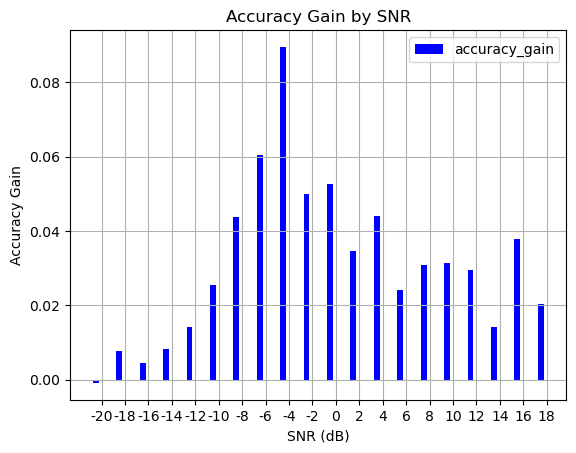

In [35]:
import numpy as np
import matplotlib.pyplot as plt
a=np.array(list(map(lambda x: acc2[x], snrs1)))
b=list(map(lambda x: acc1[x], snrs1))
y=b-a
# Sample data
snrs = snrs1  # Signal to Noise Ratios
frequency = y


# Number of groups
n_groups = len(snrs)

# Create a plot
fig, ax = plt.subplots()
index = np.arange(n_groups)
bar_width = 0.25
#plt.figure(figsize=(6, 4))

# Bar plots
rects1 = ax.bar(index,frequency, bar_width, label='accuracy_gain',color='blue')

# Labels, Title and Custom x-axis
ax.set_xlabel('SNR (dB)')
ax.set_ylabel('Accuracy Gain')
ax.set_title('Accuracy Gain by SNR')
ax.set_xticks(index + bar_width)
ax.set_xticklabels(snrs)
ax.legend()
plt.grid()
plt.savefig('gain2.png')  # Save the figure to a file

# Display plot
plt.show()

